# Notebook 03: Análisis Exploratorio de Datos (EDA)
**Proyecto:** Predicción de Insatisfacción del Cliente — Olist (Grupo C)
**Inciso 1 del enunciado:** realizar un EDA detallando las características de cada variable.

Se analiza `base_consolidada.csv` (Notebook 01): una fila por pedido entregado con reseña.
**Pasos:**
1. Clasificación de variables y diccionario.
2. Variable objetivo y desbalance.
3. Análisis univariado (numéricas, categóricas y binarias).
4. Relación de cada predictora con la insatisfacción.
5. Correlaciones y conclusiones.

Los gráficos se guardan en `informe/figuras/` para el informe.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

sys.path.append(os.path.abspath('../src'))
from preparacion import leer_base, tasa_insatisfaccion
from variables import (VARS_REFERENCIA, VAR_OBJETIVO, VARS_FUGA, VARS_BINARIAS,
                       VARS_CATEGORICAS, VARS_NUMERICAS, DESCRIPCION)
from utils import resumen_numerico, tabla_outliers

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_colwidth', 70)

RUTA_FIG = '../informe/figuras'
os.makedirs(RUTA_FIG, exist_ok=True)

# Colores fijos para todo el informe: azul = satisfecho, naranja = insatisfecho
AZUL, NARANJA = '#2a78d6', '#eb6834'

# Estilo uniforme para todos los gráficos (fondo blanco para el PDF)
pio.templates['grupo_c'] = go.layout.Template(layout=dict(
    font=dict(family='Arial', size=13, color='#0b0b0b'),
    paper_bgcolor='white', plot_bgcolor='white',
    title=dict(x=0.5, font=dict(size=16)),
    xaxis=dict(showgrid=False, linecolor='#52514e', ticks='outside'),
    yaxis=dict(gridcolor='#e6e5e1', linecolor='#52514e', zeroline=False),
    margin=dict(l=60, r=30, t=70, b=50),
))
pio.templates.default = 'plotly_white+grupo_c'

# Interactivo en VS Code + imagen estática para que se vea en GitHub
pio.renderers.default = 'vscode+png'

def guardar(fig, nombre):
    """Guarda la figura como PNG en informe/figuras para usarla en el PDF."""
    fig.write_image(os.path.join(RUTA_FIG, nombre + '.png'), scale=2)

df = leer_base('../data/procesado/base_consolidada.csv')
print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')

Filas: 95,603 | Columnas: 57


## 1. Clasificación de las variables
| Grupo | Uso |
|---|---|
| Referencia | Identificadores, fechas originales y controles de calidad. No se analizan ni se usan en el modelo |
| Objetivo | `insatisfecho`: lo que se predice |
| Reseña y entrega real (no predictoras) | Datos de la encuesta y días reales de entrega/atraso. Se usan en el EDA para entender el problema, pero **no en el modelo**: se conocen después del momento en que el modelo tiene que predecir |
| Binarias, categóricas y numéricas | Predictoras: se analizan en el EDA y se usan en el modelo |

La clasificación está en `src/variables.py` para usarla igual en todos los notebooks.

In [2]:
grupos = {
    'referencia (no predictoras)': VARS_REFERENCIA,
    'objetivo': [VAR_OBJETIVO],
    'información posterior (solo EDA)': VARS_FUGA,
    'binarias': VARS_BINARIAS,
    'categóricas': VARS_CATEGORICAS,
    'numéricas': VARS_NUMERICAS,
}
display(pd.DataFrame({'cantidad de variables': {g: len(v) for g, v in grupos.items()}}))

# Control: todas las columnas de la base deben estar clasificadas, y ninguna de más
clasificadas = sum(grupos.values(), [])
sin_clasificar = set(df.columns) - set(clasificadas)
inexistentes = set(clasificadas) - set(df.columns)

print(f'Clasificadas: {len(clasificadas)} de {df.shape[1]} columnas')
print('✔ Todas las columnas están clasificadas' if not sin_clasificar
      else f'✘ Columnas sin clasificar: {sin_clasificar}')
print('✔ No hay nombres inexistentes en variables.py' if not inexistentes
      else f'✘ Nombres que no existen en la base: {inexistentes}')

,cantidad de variables
referencia (no predictoras),15
objetivo,1
información posterior (solo EDA),7
binarias,4
categóricas,8
numéricas,22


Clasificadas: 57 de 57 columnas
✔ Todas las columnas están clasificadas
✔ No hay nombres inexistentes en variables.py


## 2. Diccionario de variables
Descripción, tipo, porcentaje de nulos y cantidad de valores únicos de cada variable analizable.

In [3]:
rol = {v: g for g, lista in grupos.items() for v in lista}

diccionario = pd.DataFrame([{
    'variable': v,
    'grupo': rol[v],
    'descripción': d,
    'tipo': str(df[v].dtype),
    '% nulos': round(df[v].isna().mean() * 100, 2),
    'valores únicos': df[v].nunique(),
} for v, d in DESCRIPCION.items()]).set_index('variable')

# Una tabla por grupo, para que se lea más fácil
for grupo, tabla in diccionario.groupby('grupo', sort=False):
    print(f'\n■ {grupo.upper()} ({len(tabla)} variables)')
    display(tabla.drop(columns='grupo'))
    
diccionario.to_csv('../data/procesado/diccionario_variables.csv')


■ OBJETIVO (1 variables)


,descripción,tipo,% nulos,valores únicos
variable,,,,
insatisfecho,"Variable objetivo: 1 si review_score es 1-3, 0 si es 4-5",int64,0.0,2



■ INFORMACIÓN POSTERIOR (SOLO EDA) (7 variables)


,descripción,tipo,% nulos,valores únicos
variable,,,,
review_score,Puntuación de la reseña (1 a 5),int64,0.0,5
tiene_comentario,1 si el cliente escribió un comentario,int64,0.0,2
largo_comentario,Cantidad de caracteres del comentario,int64,0.0,209
review_creation_date,Fecha de creación de la encuesta,datetime64[us],0.0,626
review_answer_timestamp,Fecha de respuesta de la encuesta,datetime64[us],0.0,95037
dias_entrega_real,Días reales entre la compra y la entrega,float64,0.0,92969
dias_retraso,"Entrega real - fecha estimada, en días (>0 = tarde)",float64,0.0,91111



■ BINARIAS (4 variables)


,descripción,tipo,% nulos,valores únicos
variable,,,,
entrega_tardia,1 si el pedido llegó después del día estimado,int64,0.0,2
despacho_tardio,1 si el vendedor despachó después de su fecha límite,int64,0.0,2
mismo_estado,1 si cliente y vendedor principal están en el mismo estado,int64,0.0,2
misma_region,1 si cliente y vendedor principal están en la misma región,int64,0.0,2



■ CATEGÓRICAS (8 variables)


,descripción,tipo,% nulos,valores únicos
variable,,,,
categoria_principal,Categoría del ítem más caro del pedido,str,0.0,74
tipo_pago,Medio de pago de mayor monto,str,0.0,4
customer_state,Estado (sigla) del cliente,str,0.0,27
customer_region,Región de Brasil del cliente,str,0.0,5
seller_state,Estado (sigla) del vendedor principal,str,0.0,22
seller_region,Región de Brasil del vendedor principal,str,0.0,5
mes_compra,Mes de la compra (1-12),int64,0.0,12
dia_semana_compra,Día de la semana de la compra (0 = lunes),int64,0.0,7



■ NUMÉRICAS (22 variables)


,descripción,tipo,% nulos,valores únicos
variable,,,,
dias_entrega_observados,Días de entrega hasta el momento de predicción,float64,0.00,92916
dias_anticipacion,Días que llegó antes de la fecha estimada (0 si se atrasó),float64,0.00,83569
dias_entrega_estimada,"Plazo de entrega prometido, en días",float64,0.00,93055
horas_aprobacion,Horas entre la compra y la aprobación del pago,float64,0.01,32392
dias_hasta_transportista,Días entre la compra y el despacho al transportista,float64,0.00,86647
dias_despacho_vs_limite,"Despacho - fecha límite de despacho, en días (>0 = tarde)",float64,0.00,89274
cant_items,Cantidad de ítems del pedido,int64,0.00,17
cant_productos,Cantidad de productos distintos,int64,0.00,8
cant_vendedores,Cantidad de vendedores distintos,int64,0.00,5


## 3. Variable objetivo

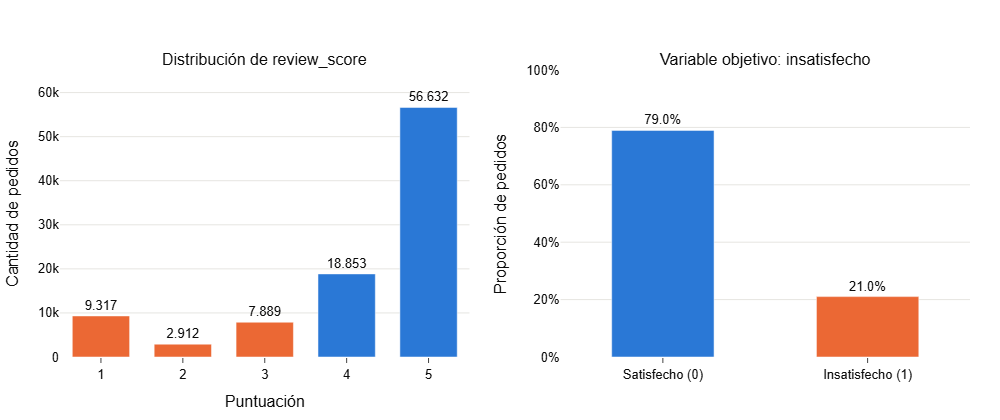

Razón de desbalance: 3.8 satisfechos por cada insatisfecho


In [4]:
conteo = df['review_score'].value_counts().sort_index()
prop = df[VAR_OBJETIVO].value_counts(normalize=True).sort_index()

fig = make_subplots(rows=1, cols=2,
                    subplot_titles=('Distribución de review_score', 'Variable objetivo: insatisfecho'))

# Izquierda: puntuación original, coloreada según la clase que genera
fig.add_trace(go.Bar(
    x=conteo.index, y=conteo.values,
    marker_color=[NARANJA if s <= 3 else AZUL for s in conteo.index],
    text=[f'{v:,}'.replace(',', '.') for v in conteo.values], textposition='outside',
    hovertemplate='Puntuación %{x}<br>%{y:,} pedidos<extra></extra>',
), row=1, col=1)

# Derecha: variable objetivo binaria
fig.add_trace(go.Bar(
    x=['Satisfecho (0)', 'Insatisfecho (1)'], y=prop.values, width=0.5,
    marker_color=[AZUL, NARANJA],
    text=[f'{v:.1%}' for v in prop.values], textposition='outside',
    hovertemplate='%{x}<br>%{y:.1%} de los pedidos<extra></extra>',
), row=1, col=2)

fig.update_xaxes(title_text='Puntuación', dtick=1, row=1, col=1)
fig.update_yaxes(title_text='Cantidad de pedidos', range=[0, conteo.max() * 1.15], row=1, col=1)
fig.update_yaxes(title_text='Proporción de pedidos', tickformat='.0%', range=[0, 1], row=1, col=2)
fig.update_layout(showlegend=False, height=420, width=1000, bargap=0.3)

guardar(fig, '03_01_variable_objetivo')
fig.show()

print(f'Razón de desbalance: {prop[0] / prop[1]:.1f} satisfechos por cada insatisfecho')